# TD : RAG 

Ce TD est divisé en plusieurs parties et traite de la construction d'un RAG :
1. Récupèration d'un corpus
2. Différente méthode de chunking
3. Embeddings, vecteurs et similarité 
4. Ingestion avec Qdrant
5. Retrieval 
6. Reranking

* Corpus [BEIR](https://huggingface.co/datasets/BeIR/hotpotqa?utm_source=chatgpt.com)
* Corpus [Narrativeqa-RAG](https://huggingface.co/datasets/DinoStackAI/narrativeqa-rag?utm_source=chatgpt.com)
* Vector DB [Qdrant](https://qdrant.tech/documentation/quickstart/)


Pour démarrer Qdrant:

```bash
docker pull qdrant/qdrant
```


```bash
docker run -p 6333:6333 -p 6334:6334 \
    -v "$(pwd)/qdrant_storage:/qdrant/storage:z" \
    qdrant/qdrant
```
Web UI : http://localhost:6333/dashboard#/welcome

In [1]:
from datasets import load_dataset
import numpy as np
import matplotlib.pyplot as plt

## 1. Chargez un corpus et garder un sous-ensemble 

Ici on charge le corpus BEIR via HF (api datasets), et on garde un sous-ensemble de texte pour la suite

In [2]:
corpus  = load_dataset(
    "DinoStackAI/narrativeqa-rag",
    "corpus",
    split="train",
    streaming=True,
)

In [3]:
print(corpus)

IterableDataset({
    features: ['id', 'title', 'text'],
    num_shards: 1
})


In [4]:
for doc in corpus.take(3):
    print(doc["id"]) # get id 
    print(doc["title"]) # get title 
    print(doc["text"][:300]) # get text
    print("---")

0025577043f5090cd603c6aea60f26e236195594
Pump Up the Volume (film)
 Mark Hunter (Slater), a high school student in a sleepy suburb of Phoenix, Arizona, starts an FM pirate radio station that broadcasts from the basement of his parents' house. Mark is a loner, an outsider, whose only outlet for his teenage angst and aggression is his unauthorized radio station. His 
---
0029bdbe75423337b551e42bb31f9a102785376f
Percival Keene
 At Madeline Hall, an old mansion-house near Southampton belonging to the wealthy de Versely family, lives an elderly spinster Miss Delmar, the aunt of the earl de Versely and Captain Delmar. Miss Delmar invites Arabella Mason, the daughter of a deceased, well-liked steward to stay with her as a low
---
00936497f5884881f1df23f4834f6739552cee8b
Five Weeks in a Balloon
 A scholar and explorer, Dr. Samuel Ferguson, accompanied by his manservant Joe and his friend professional hunter Richard "Dick" Kennedy, sets out to travel across the African continent — still not ful

In [5]:
### Garder un subset pour la construction du RAG

N_docs = 500
SEED = 42 # pour la reproductibilité 

shuffle_corpus = corpus.shuffle(
    seed=SEED, 
    buffer_size=10000
)


In [6]:
small_corpus = []
for doc in shuffle_corpus.take(N_docs):
    small_corpus.append({
        "doc_id":doc["id"], 
        "title":doc["title"],
        "text":doc["text"]
    })

## 2. Chunking

Dans cette section on va voir différente méthode de chunking afin de séparer un texte en chunk (morceaux de texte). On va voir 3 stratégies : 
1. Taille fixe 
2. Avec recouvrement
3. Par phrase (ou paragraphe)


Nombre de documents : 500
Moyenne : 573.8 mots
Médiane : 598.0 mots
Minimum : 200 mots
Maximum : 999 mots


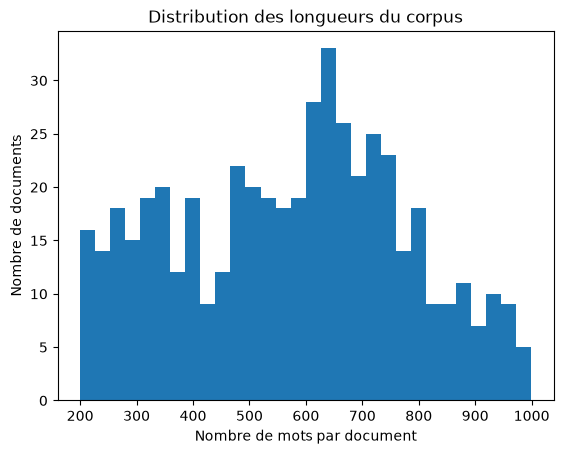

In [7]:
## Représentation graphique de la taille de chaque texte  : 

doc_lengths = [
    len(doc["text"].split())
    for doc in small_corpus
]

print(f"Nombre de documents : {len(doc_lengths)}")
print(f"Moyenne : {np.mean(doc_lengths):.1f} mots")
print(f"Médiane : {np.median(doc_lengths):.1f} mots")
print(f"Minimum : {np.min(doc_lengths)} mots")
print(f"Maximum : {np.max(doc_lengths)} mots")

plt.hist(doc_lengths, bins=30)
plt.xlabel("Nombre de mots par document")
plt.ylabel("Nombre de documents")
plt.title("Distribution des longueurs du corpus")
plt.show()

1. Chunk par taille fixe 

Définir un fonction qui prend en input un texte et un nombre de mots, et renvoie une liste de chunks de taille fixe 

In [8]:
def chunk_fixed(text, chunk_size=150):
    words = text.split()
    chunks = []
    
    for start in range(0, len(words), chunk_size):
        chunks.append(" ".join(words[start:start+chunk_size]))
        
    return chunks


In [9]:
text = small_corpus[0]["text"]

chunks = chunk_fixed(text, chunk_size=100)

print(*chunks, sep="\n\n")

In the beginning, Columbus is obsessed with making a trip westwards to Asia, but lacks crew and a ship. The Catholic theologians at the University of Salamanca heavily disapprove of it, and they are not keen on ideas that go against the writings of Ptolemaeus. After continuous warnings at the monastery, he becomes involved in a brawl with the monks, ending up lying in the monastery courtyard to pay penance. His eldest son, Diego, one of the monks, looks on disapprovingly. As Columbus continues his penance through a vow of silence, he is approached by Martín Pinzon, a shipowner from

Palos, who introduces Columbus to the banker Santángel. Queen Isabella I (Sigourney Weaver) owes money to Santángel. Columbus meets with the queen, who grants him his journey in exchange for his promise to bring back sufficient amounts of riches in gold. Columbus tricks many crewmen by telling them that the voyage would only last seven weeks. He goes to confession at the monastery to absolve his sins, and t

2. Chunk avec overlap 

Définir un fonction qui prend en input un texte, un nombre de mots et un overlap (le n derniers mots d'un chunk sont les n premiers du chunk suivant), et renvoie une liste de chunks

In [10]:
def chunk_overlap(text, chunk_size=150, overlap=20):
    words = text.split()
    chunks = []
    
    if overlap >= chunk_size:
        print("Overlap should be lower than chunk_size")
        return chunks
    
    for start in range(0, len(words), chunk_size):
        if start == 0:
            chunks.append(" ".join(words[start:start+chunk_size]))
        else:
            chunks.append(" ".join(words[start-overlap:start+chunk_size]))
            
    return chunks

In [11]:
chunks_overlap = chunk_overlap(text, chunk_size=100)

print(*chunks_overlap, sep="\n\n")

In the beginning, Columbus is obsessed with making a trip westwards to Asia, but lacks crew and a ship. The Catholic theologians at the University of Salamanca heavily disapprove of it, and they are not keen on ideas that go against the writings of Ptolemaeus. After continuous warnings at the monastery, he becomes involved in a brawl with the monks, ending up lying in the monastery courtyard to pay penance. His eldest son, Diego, one of the monks, looks on disapprovingly. As Columbus continues his penance through a vow of silence, he is approached by Martín Pinzon, a shipowner from

disapprovingly. As Columbus continues his penance through a vow of silence, he is approached by Martín Pinzon, a shipowner from Palos, who introduces Columbus to the banker Santángel. Queen Isabella I (Sigourney Weaver) owes money to Santángel. Columbus meets with the queen, who grants him his journey in exchange for his promise to bring back sufficient amounts of riches in gold. Columbus tricks many crewme

3. Chunk part phrase 

Définir un fonction qui prend en input un texte, de phrase et renvoie une liste de chunks

In [12]:
def chunk_sentence(text, chunk_size=1): # chunk_size = nb de phrase
    sentences = text.split('.')
    chunks = []
    
    for start in range(0, len(sentences), chunk_size):
        chunks.append(" ".join(sentences[start:start+chunk_size]))
        
    return chunks

In [13]:
chunks_sentence = chunk_sentence(text)

print(*chunks_sentence, sep="\n\n")

 In the beginning, Columbus is obsessed with making a trip westwards to Asia, but lacks crew and a ship

 The Catholic theologians at the University of Salamanca heavily disapprove of it, and they are not keen on ideas that go against the writings of Ptolemaeus

 After continuous warnings at the monastery, he becomes involved in a brawl with the monks, ending up lying in the monastery courtyard to pay penance

 His eldest son, Diego, one of the monks, looks on disapprovingly

 As Columbus continues his penance through a vow of silence, he is approached by Martín Pinzon, a shipowner from Palos, who introduces Columbus to the banker Santángel

 Queen Isabella I (Sigourney Weaver) owes money to Santángel

 Columbus meets with the queen, who grants him his journey in exchange for his promise to bring back sufficient amounts of riches in gold


Columbus tricks many crewmen by telling them that the voyage would only last seven weeks

 He goes to confession at the monastery to absolve his sin

4. Corpus et chunks 

Il est temps de constituer le corpus de chunks. Constituer l'un ensemble des chunks à partir du small_corpus, en gardant les infos sur le texte originale (id, title) et la place du chunk dans le texte. 

On pourra tester les différentes méthodes ainsi que la méthode sans chunk. 

In [14]:
cor_chunks = []
for instance in small_corpus:
    cor_chunks.append(
        {
            "doc_id": instance["doc_id"],
            "title": instance["title"],
            "chunk": instance["text"],
            "chunk_id": 0,
        }
    )

cor_chunks_fixed = []

for instance in small_corpus:
    chunks = chunk_fixed(instance["text"], chunk_size=100)

    for i, chunk in enumerate(chunks):
        cor_chunks_fixed.append(
            {
                "doc_id": instance["doc_id"],
                "title": instance["title"],
                "chunk": chunk,
                "chunk_id": i,
            }
        )
        
cor_chunks_overlap= []

for instance in small_corpus:
    chunks = chunk_overlap(instance["text"], chunk_size=100, overlap=20)

    for i, chunk in enumerate(chunks):
        cor_chunks_overlap.append(
            {
                "doc_id": instance["doc_id"],
                "title": instance["title"],
                "chunk": chunk,
                "chunk_id": i,
            }
        )
        
cor_chunks_sentence = []

for instance in small_corpus:
    chunks = chunk_sentence(instance["text"], chunk_size=2)

    for i, chunk in enumerate(chunks):
        cor_chunks_sentence.append(
            {
                "doc_id": instance["doc_id"],
                "title": instance["title"],
                "chunk": chunk,
                "chunk_id": i,
            }
        )

In [15]:
print("no chunking size:", len(cor_chunks))

print("Fixed chunking size:", len(cor_chunks_fixed))
print("overlape chunking size:", len(cor_chunks_overlap))
print("Sentence chunking size:", len(cor_chunks_sentence))

no chunking size: 500
Fixed chunking size: 3127
overlape chunking size: 3127
Sentence chunking size: 7682


## 3. Embedding, vecteur et similarité 

In [16]:
from sentence_transformers import SentenceTransformer

MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"

In [17]:
embedding_model = SentenceTransformer(MODEL_NAME)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [18]:

print("Model:", MODEL_NAME)
print("Embedding dimension:", embedding_model.get_embedding_dimension())
print("Max sequence length:", embedding_model.max_seq_length, "tokens")

Model: sentence-transformers/all-MiniLM-L6-v2
Embedding dimension: 384
Max sequence length: 256 tokens


In [19]:
## Pour encoder une phrase :
embedding = embedding_model.encode(text)
print(embedding)

[ 1.84779055e-03  1.15493583e-02 -4.15941104e-02  1.26889437e-01
  1.73469111e-02 -2.00966522e-02  5.28759807e-02 -3.16833146e-02
  2.68728100e-03 -1.79139208e-02 -2.34306548e-02 -1.28519209e-02
 -8.32907408e-02  1.21150296e-02 -4.59729768e-02  4.24906537e-02
 -5.14021702e-02 -1.20870080e-02 -1.63009297e-02  9.65203419e-02
 -1.08837383e-02 -1.04271524e-01 -4.92665656e-02  9.28668603e-02
  1.01927528e-02  2.61925347e-03  5.16275037e-03 -1.02153115e-01
 -4.63710018e-02 -2.01204401e-02 -8.94577280e-02 -1.70495138e-02
  2.60402765e-02 -1.28625855e-02 -1.06509114e-02  3.50847468e-02
  6.42782524e-02 -2.36980040e-02 -1.71737969e-02 -4.68832068e-02
  9.95461177e-03  2.71867476e-02 -3.42990784e-03  1.09599605e-01
 -7.46601075e-02 -1.19202897e-01 -1.26997512e-02  4.15582471e-02
  4.89221960e-02  2.17151213e-02 -3.68433371e-02 -2.78275851e-02
 -1.51471961e-02 -5.30865975e-02 -6.93992227e-02  6.55844286e-02
 -7.82577321e-04 -3.45834605e-02  7.82238021e-02  4.16475311e-02
  6.06422424e-02  4.34427

Encoder les chunks du corpus (choisir la méthode de chunking). Construire un corpus avec, pour chaque instance, *doc_id*, *title*, *chunk*, *chunk_id* et *embedding*

In [20]:
embedding_corpus = []

for i, instance in enumerate(small_corpus):
    print(i, end="\r")
    text = instance["text"]
    chunks = chunk_overlap(text, chunk_size=200, overlap=20)

    for i, chunk in enumerate(chunks):
        embedding_corpus.append(
            {
                "doc_id": instance["doc_id"],
                "title": instance["title"],
                "chunk": chunk,
                "chunk_id": i,
                "embedding": embedding_model.encode(text),
            }
        )

In [21]:
embedding_corpus[:10]

[{'doc_id': 'c41dba67fbd19688656d31ccffec145c12f15b94',
  'title': '1492: Conquest of Paradise',
  'chunk': 'In the beginning, Columbus is obsessed with making a trip westwards to Asia, but lacks crew and a ship. The Catholic theologians at the University of Salamanca heavily disapprove of it, and they are not keen on ideas that go against the writings of Ptolemaeus. After continuous warnings at the monastery, he becomes involved in a brawl with the monks, ending up lying in the monastery courtyard to pay penance. His eldest son, Diego, one of the monks, looks on disapprovingly. As Columbus continues his penance through a vow of silence, he is approached by Martín Pinzon, a shipowner from Palos, who introduces Columbus to the banker Santángel. Queen Isabella I (Sigourney Weaver) owes money to Santángel. Columbus meets with the queen, who grants him his journey in exchange for his promise to bring back sufficient amounts of riches in gold. Columbus tricks many crewmen by telling them th

## 4. Vector DB et ingestion 

Avec Qdrant :
- créer une collection 
- stocker les embeddings et les payloads 

In [32]:
from qdrant_client import QdrantClient, models
from qdrant_client.models import PointStruct

In [23]:
client = QdrantClient(url="http://localhost:6333")
print(client.get_collections())

collections=[]


In [29]:
## Créer une collection 

COLLECTION_NAME = "TD_6_collection"
VECTOR_SIZE = embedding_corpus[0]["embedding"].shape[0]

print(VECTOR_SIZE)

384


In [31]:
if client.collection_exists(COLLECTION_NAME):
    client.delete_collection(COLLECTION_NAME)
    print(f"Collection {COLLECTION_NAME} supprimée.")
    
res = client.create_collection(
    collection_name=COLLECTION_NAME, 
    vectors_config=models.VectorParams(
        size=VECTOR_SIZE, 
        distance=models.Distance.COSINE ## Distance utiliser pour le retrieval
    )
)

if res:
    print(f"Collection {COLLECTION_NAME} créée.")

Collection TD_6_collection supprimée.
Collection TD_6_collection créée.


In [48]:
## ajouter les embeddings à la collection
## 1. Créer les points


points = []

for i, instance in enumerate(embedding_corpus):
    points.append(
        PointStruct(
            id=i,  ### identifiant du chunk dans la vector DB, on pourra ausis utiser un UUID dans des plus grosses DB 
            vector=instance["embedding"].tolist(), 
            payload={
                "doc_id":instance["doc_id"], 
                "chunk_id": instance["chunk_id"], 
                "title":instance["title"], 
                "chunk":instance["chunk"],
                #"text":instance["text"]
            }
        )
    )


KeyError: 'text'

In [41]:
## 2. Ajouter les points à la collection

client.upsert(collection_name=COLLECTION_NAME, points=points)

print(f"Ingestion des {len(embedding_corpus)} points dans la collection {COLLECTION_NAME} terminée")

Ingestion des 1693 points dans la collection TD_6_collection terminée


In [42]:
collection_info = client.get_collection(COLLECTION_NAME)

print("Points dans Qdrant :", collection_info.points_count)
print("Points préparés :", len(points))

Points dans Qdrant : 1693
Points préparés : 1693


## 5. Retrieval 

1. Se connecter au client 
2. Vérifier que la collection existe 
3. Définir une fonction de **retrieve** et effectuer une recherche
4. Charger une passe de questions 

In [46]:
## 1. Se connecter au client 

client = QdrantClient(url="http://localhost:6333")

## 2. Vériier que la collection existe
COLLECTION_NAME = "TD_6_collection"
#print(client.get_collections())
if client.collection_exists(COLLECTION_NAME):
    print(f"La collection '{COLLECTION_NAME}' existe")
else:
    print(f"La collection '{COLLECTION_NAME}' n'existe pas")


La collection 'TD_6_collection' existe


In [66]:
## 3. Définir une fonction de retrieval

def retrieval(query, client, collection_name, embedding_model, top_k=5):
    # 1. Encoder la question
    query_embedding = embedding_model.encode(
        query
    )
    
    # 2. Recherche les chunks dans Qdrant
    response = client.query_points(
        collection_name=collection_name, 
        query=query_embedding.tolist(), 
        limit=top_k, 
        with_payload=True
    )
    
    return [
        {
            "rank": rank,
            "score": point.score,
            "chunk_id": point.payload.get("chunk_id"),
            "doc_id": point.payload.get("doc_id"),
            "title": point.payload.get("title"),
            "chunk":point.payload.get("chunk")
        }
        for rank, point in enumerate(response.points, start=1)
    ]  

In [67]:
## Effectuer une recherche : 

query = "What causes the seasons on Earth?"

hits = retrieval(
    query=query,
    client=client,
    collection_name=COLLECTION_NAME,
    embedding_model=embedding_model,
    top_k=5
)

In [68]:
import pandas as pd

df_hits = pd.DataFrame([
    {
        "rank": hit["rank"],
        "score": round(hit["score"], 4),
        "title": hit["title"],
        "doc_id": hit["doc_id"],
        "chunk": hit["chunk"]
    }
    for hit in hits
])

df_hits

,rank,score,title,doc_id,chunk
0,1,0.2347,Wolfbane (novel),d12193f0306f5697bc5568e62349f54b9f1989dd,This science fiction novel takes place in the ...
1,2,0.2347,Wolfbane (novel),d12193f0306f5697bc5568e62349f54b9f1989dd,"who lives among the Citizens, but regards hims..."
2,3,0.2347,Wolfbane (novel),d12193f0306f5697bc5568e62349f54b9f1989dd,"condition, Tropile wakes, manages to retain hi..."
3,4,0.2347,Wolfbane (novel),d12193f0306f5697bc5568e62349f54b9f1989dd,ritual execution. A small minority of the popu...
4,5,0.2347,Wolfbane (novel),d12193f0306f5697bc5568e62349f54b9f1989dd,number is taken over by the mind of the alien ...
